# LoRaSeek Standalone Symbol Demodulation Test
This notebook tests **LoRaSeek** symbol demodulation accuracy under standalone conditions:
* **Modulation Parameters**: SF = 7, Bandwidth = 125 kHz, Sampling Rate = 1 MHz
* **Channel Impairments**: Pure AWGN at **SNR = -16 dB** (No CFO, No STO timing offset)
* **Symbol Count**: Generates many random ground-truth LoRa symbols ($0$ to $2^{SF}-1$)
* **Evaluated Models**:
  1. **LoRaSeek (75,000 iterations)** — Best checkpoint
  2. **LoRaSeek (90,000 iterations)** — Default checkpoint
  3. **Conventional Dechirping** — Classical baseline for comparison


In [9]:
import sys
import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
from tqdm import tqdm
import importlib

# Ensure Server root is on sys.path
notebook_dir = Path(os.path.abspath('')).resolve()
if notebook_dir.name != 'Server':
    server_dir = notebook_dir / 'Server'
else:
    server_dir = notebook_dir

if str(server_dir) not in sys.path:
    sys.path.insert(0, str(server_dir))

from utils.LoRa import LoRa
from utils import loraseek_inference
importlib.reload(loraseek_inference)  # Force reload latest inference code
from dashboard.orchestrator import calculate_symbol_alliqfile_with_down_sampling

print('LoRaSeek inference module loaded and reloaded successfully.')
print(f'Using compute device: {loraseek_inference.DEVICE}')
print(f'Available LoRaSeek checkpoints: {loraseek_inference.list_loraseek_checkpoints()}')


LoRaSeek inference module loaded and reloaded successfully.
Using compute device: cpu
Available LoRaSeek checkpoints: [{'filename': '90000_LoRaSeek.pkl', 'label': '90000 iterations (default)', 'is_default': True, 'exists': True}, {'filename': '75000_LoRaSeek.pkl', 'label': '75000 iterations (best model)', 'is_default': False, 'exists': True}]


In [10]:
# --------------------------------------------------------------------------
# Configuration Parameters
# --------------------------------------------------------------------------
SF = 7                # Spreading Factor
BW = 125_000          # Bandwidth: 125 kHz
FS = 1_000_000        # Sampling Frequency: 1 MHz
SNR_DB = -20          # Channel SNR: -16 dB AWGN
N_SYMBOLS = 1200       # Number of random symbols to test (adjust as desired)
RANDOM_SEED = 0      # Reproducibility seed

N_CLASSES = 2 ** SF                    # 128 possible symbols (0 to 127)
SAMPLES_PER_SYMBOL = N_CLASSES * (FS // BW)  # 1024 samples per symbol

print('=' * 65)
print('EXPERIMENT CONFIGURATION')
print('=' * 65)
print(f'  * Spreading Factor (SF)   : {SF} ({N_CLASSES} symbols: 0..{N_CLASSES - 1})')
print(f'  * Bandwidth (BW)          : {BW:,} Hz')
print(f'  * Sampling Frequency (FS) : {FS:,} Hz ({FS // BW}x oversampled)')
print(f'  * Samples per Symbol      : {SAMPLES_PER_SYMBOL} samples')
print(f'  * Channel Noise           : AWGN at {SNR_DB} dB (Pure noise, zero CFO, zero STO)')
print(f'  * Test Sample Count       : {N_SYMBOLS} random symbols')
print('=' * 65)


EXPERIMENT CONFIGURATION
  * Spreading Factor (SF)   : 7 (128 symbols: 0..127)
  * Bandwidth (BW)          : 125,000 Hz
  * Sampling Frequency (FS) : 1,000,000 Hz (8x oversampled)
  * Samples per Symbol      : 1024 samples
  * Channel Noise           : AWGN at -20 dB (Pure noise, zero CFO, zero STO)
  * Test Sample Count       : 1200 random symbols


In [11]:
# --------------------------------------------------------------------------
# Generate Random Symbols & Pure AWGN Noisy Signals
# --------------------------------------------------------------------------
np.random.seed(RANDOM_SEED)
lora = LoRa(sf=SF, bw=BW)

# 1. Generate random ground truth symbols
gt_symbols = np.random.randint(0, N_CLASSES, size=N_SYMBOLS)

clean_signals = []
noisy_signals = []

for idx, sym in enumerate(gt_symbols):
    clean_sym = lora.gen_symbol_fs(code_word=int(sym), down=False, Fs=FS)
    seed_val = (int(RANDOM_SEED) + idx) % (2**32 - 1)
    noisy_sym = lora.awgn_iq_with_seed(clean_sym, SNR_=SNR_DB, seed=seed_val)
    clean_signals.append(clean_sym)
    noisy_signals.append(noisy_sym)

print(f'Successfully generated {N_SYMBOLS} symbols at SNR = {SNR_DB} dB.')
print(f'Signal shape: {noisy_signals[0].shape}, dtype: {noisy_signals[0].dtype}')
measured_snr = lora.calculate_snr_db(clean_signals[0], noisy_signals[0])
print(f'Sample #0 Target SNR: {SNR_DB} dB | Measured SNR: {measured_snr:.2f} dB')


Successfully generated 1200 symbols at SNR = -20 dB.
Signal shape: (1024,), dtype: complex64
Sample #0 Target SNR: -20 dB | Measured SNR: -19.80 dB


In [12]:
# --------------------------------------------------------------------------
# Test 1: LoRaSeek (75,000 Checkpoint - Best Model)
# Uses batch processing for high throughput
# --------------------------------------------------------------------------
batch_size = 100
pred_ls_75k = []

for i in tqdm(range(0, N_SYMBOLS, batch_size), desc='LoRaSeek (75k)'):
    chunk = np.concatenate(noisy_signals[i : i + batch_size])
    preds = loraseek_inference.demodulate_payload_loraseek(
        chunk, sf=SF, bw=BW, fs=FS, checkpoint_name='75000_LoRaSeek.pkl'
    )
    pred_ls_75k.extend(preds)

pred_ls_75k = np.array(pred_ls_75k)
correct_ls_75k = int(np.sum(pred_ls_75k == gt_symbols))
acc_ls_75k = (correct_ls_75k / N_SYMBOLS) * 100.0

print(f'\n[LoRaSeek 75k Results @ {SNR_DB} dB]')
print(f'  * Correct Symbols : {correct_ls_75k} / {N_SYMBOLS}')
print(f'  * Accuracy Rate   : {acc_ls_75k:.2f}%')


LoRaSeek (75k): 100%|██████████| 12/12 [01:59<00:00,  9.96s/it]


[LoRaSeek 75k Results @ -20 dB]
  * Correct Symbols : 892 / 1200
  * Accuracy Rate   : 74.33%


In [13]:
# --------------------------------------------------------------------------
# Test 2: LoRaSeek (90,000 Checkpoint)
# Uses batch processing for high throughput
# --------------------------------------------------------------------------
batch_size = 100
pred_ls_90k = []

for i in tqdm(range(0, N_SYMBOLS, batch_size), desc='LoRaSeek (90k)'):
    chunk = np.concatenate(noisy_signals[i : i + batch_size])
    preds = loraseek_inference.demodulate_payload_loraseek(
        chunk, sf=SF, bw=BW, fs=FS, checkpoint_name='90000_LoRaSeek.pkl'
    )
    pred_ls_90k.extend(preds)

pred_ls_90k = np.array(pred_ls_90k)
correct_ls_90k = int(np.sum(pred_ls_90k == gt_symbols))
acc_ls_90k = (correct_ls_90k / N_SYMBOLS) * 100.0

print(f'\n[LoRaSeek 90k Results @ {SNR_DB} dB]')
print(f'  * Correct Symbols : {correct_ls_90k} / {N_SYMBOLS}')
print(f'  * Accuracy Rate   : {acc_ls_90k:.2f}%')


LoRaSeek (90k): 100%|██████████| 12/12 [02:11<00:00, 10.92s/it]


[LoRaSeek 90k Results @ -20 dB]
  * Correct Symbols : 864 / 1200
  * Accuracy Rate   : 72.00%


In [14]:
# --------------------------------------------------------------------------
# Test 3: Conventional Dechirping Baseline
# --------------------------------------------------------------------------
pred_conv = []

for i in tqdm(range(N_SYMBOLS), desc='Conventional'):
    pred = calculate_symbol_alliqfile_with_down_sampling(
        noisy_signals[i], sf=SF, bw=BW, sample_rate=FS, show=False
    )[0]
    pred_conv.append(pred)

pred_conv = np.array(pred_conv)
correct_conv = int(np.sum(pred_conv == gt_symbols))
acc_conv = (correct_conv / N_SYMBOLS) * 100.0

print(f'\n[Conventional Dechirping Results @ {SNR_DB} dB]')
print(f'  * Correct Symbols : {correct_conv} / {N_SYMBOLS}')
print(f'  * Accuracy Rate   : {acc_conv:.2f}%')


Conventional: 100%|██████████| 1200/1200 [00:00<00:00, 3129.35it/s]


[Conventional Dechirping Results @ -20 dB]
  * Correct Symbols : 1091 / 1200
  * Accuracy Rate   : 90.92%


DEMODULATION PERFORMANCE SUMMARY (SNR = -20 dB, 1200 SYMBOLS)
Method                           | Correct      | Accuracy (%)
-----------------------------------------------------------------
LoRaSeek (75000_LoRaSeek.pkl)    |  892/1200   |  74.33%
LoRaSeek (90000_LoRaSeek.pkl)    |  864/1200   |  72.00%
Conventional Dechirping          | 1091/1200   |  90.92%


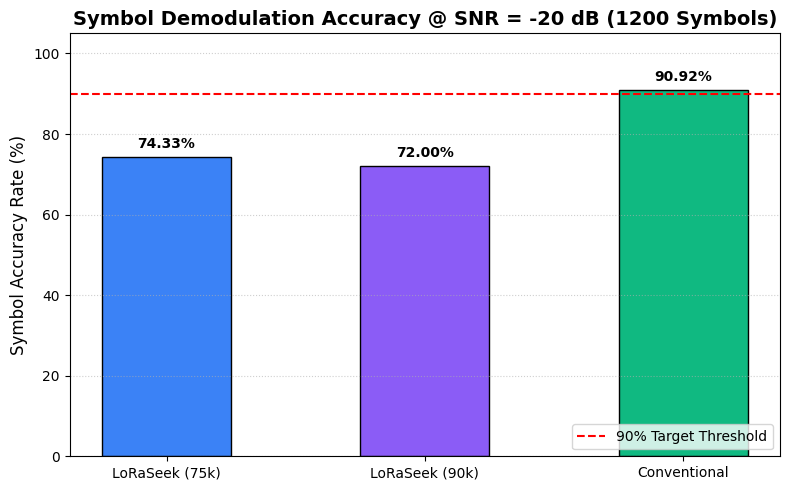

In [15]:
# --------------------------------------------------------------------------
# Summary Results Table & Visualization
# --------------------------------------------------------------------------
print('=' * 65)
print(f'DEMODULATION PERFORMANCE SUMMARY (SNR = {SNR_DB} dB, {N_SYMBOLS} SYMBOLS)')
print('=' * 65)
print(f'{"Method":<32} | {"Correct":<12} | {"Accuracy (%)":<12}')
print('-' * 65)
print(f'{"LoRaSeek (75000_LoRaSeek.pkl)":<32} | {correct_ls_75k:>4}/{N_SYMBOLS:<6} | {acc_ls_75k:>6.2f}%')
print(f'{"LoRaSeek (90000_LoRaSeek.pkl)":<32} | {correct_ls_90k:>4}/{N_SYMBOLS:<6} | {acc_ls_90k:>6.2f}%')
print(f'{"Conventional Dechirping":<32} | {correct_conv:>4}/{N_SYMBOLS:<6} | {acc_conv:>6.2f}%')
print('=' * 65)

# Plot Comparison Bar Chart
methods = ['LoRaSeek (75k)', 'LoRaSeek (90k)', 'Conventional']
accuracies = [acc_ls_75k, acc_ls_90k, acc_conv]
colors = ['#3b82f6', '#8b5cf6', '#10b981']

plt.figure(figsize=(8, 5))
bars = plt.bar(methods, accuracies, color=colors, width=0.5, edgecolor='black', linewidth=1)
plt.axhline(90, color='red', linestyle='--', linewidth=1.5, label='90% Target Threshold')
plt.ylim(0, 105)
plt.ylabel('Symbol Accuracy Rate (%)', fontsize=12)
plt.title(f'Symbol Demodulation Accuracy @ SNR = {SNR_DB} dB ({N_SYMBOLS} Symbols)', fontsize=14, fontweight='bold')
plt.grid(axis='y', linestyle=':', alpha=0.6)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 1.5, f'{yval:.2f}%', ha='center', va='bottom', fontweight='bold')

plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


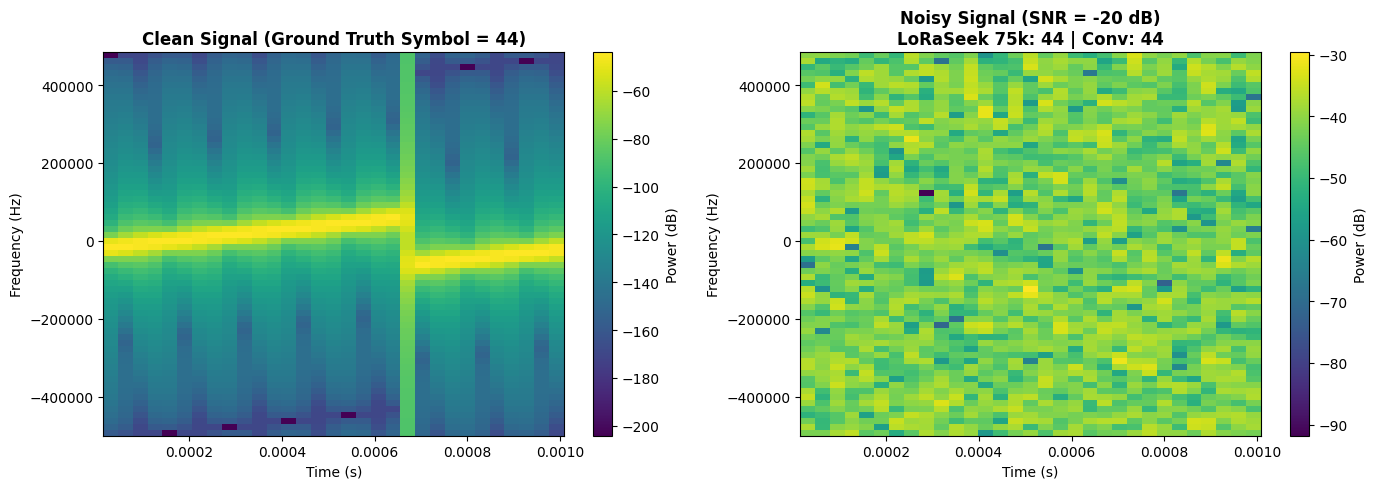

In [16]:
# --------------------------------------------------------------------------
# Spectrogram Inspection: Noisy vs. Clean for Sample #0
# --------------------------------------------------------------------------
sample_idx = 0
clean_samp = clean_signals[sample_idx]
noisy_samp = noisy_signals[sample_idx]
gt_val = gt_symbols[sample_idx]
pred_val_75k = pred_ls_75k[sample_idx]
pred_val_conv = pred_conv[sample_idx]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Clean Spectrogram
Pxx_c, freqs_c, bins_c, im_c = axes[0].specgram(clean_samp, NFFT=64, noverlap=32, Fs=FS, cmap='viridis')
axes[0].set_title(f'Clean Signal (Ground Truth Symbol = {gt_val})', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Time (s)')
axes[0].set_ylabel('Frequency (Hz)')
fig.colorbar(im_c, ax=axes[0], label='Power (dB)')

# Noisy Spectrogram (-16 dB)
Pxx_n, freqs_n, bins_n, im_n = axes[1].specgram(noisy_samp, NFFT=64, noverlap=32, Fs=FS, cmap='viridis')
axes[1].set_title(f'Noisy Signal (SNR = {SNR_DB} dB)\nLoRaSeek 75k: {pred_val_75k} | Conv: {pred_val_conv}', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('Frequency (Hz)')
fig.colorbar(im_n, ax=axes[1], label='Power (dB)')

plt.tight_layout()
plt.show()
